In [1]:
import numpy as np
import matplotlib.pyplot as plt
#%matplotlib inline
#%pip install scikit-learn
from sklearn.decomposition import PCA

In [2]:
fileName = "Out/lawnmower_data.npz"
meth_data = np.load(fileName)

cleanData = meth_data['y_clean']
noisyData = meth_data['y_noisy']
noiseLevels = meth_data['noise_sigmas_ppm']
sampleTimes = meth_data['t']
sampleLocations = meth_data['traj']

## Check the dimensions and available noise levels ##
print('Shape of Clean Data:', cleanData.shape)
print('Shape of Noisy Data:', noisyData.shape)
print('Sensor Noise Levels (ppm):', noiseLevels)
print('Shape of Sampling Locations:', sampleLocations.shape)

Shape of Clean Data: (2121,)
Shape of Noisy Data: (3, 100, 2121)
Sensor Noise Levels (ppm): [0.01 0.05 0.1 ]
Shape of Sampling Locations: (2121, 3)


### Data Cleaning and Exploration

In [3]:
## Check for NA values ##
print('Missing Values in Clean Data:', np.isnan(cleanData).sum())
print('Missing Values in Noisy Data:', np.isnan(noisyData).sum())
print('Missing Values in Sampling Locations:', np.isnan(sampleLocations).sum())
# 0 missing values! #

print('')

## Checking for infinite values below: ##
print('Infinite Values in Clean Data:', np.isinf(cleanData).sum())
print('Infinite Values in Noisy Data:', np.isinf(noisyData).sum())
# 0 infinite values! #

print('')

## Lets look at concentration ranges ##
print('Clean Concentration Minmum:', cleanData.min())
print('Clean Concentration Maximum:', cleanData.max())
# Min --> 0.0; Max --> ~0.61

print('')

for i in range(len(noiseLevels)):
    print('Noise Level (ppm):', noiseLevels[i])
    print('Noise Concentration Minmum:', noisyData[i].min())
    print('Noise Concentration Maximum:', noisyData[i].max())
    # Values seen below #

Missing Values in Clean Data: 0
Missing Values in Noisy Data: 0
Missing Values in Sampling Locations: 0

Infinite Values in Clean Data: 0
Infinite Values in Noisy Data: 0

Clean Concentration Minmum: 0.0
Clean Concentration Maximum: 0.60805372101939

Noise Level (ppm): 0.01
Noise Concentration Minmum: -0.045939901953957724
Noise Concentration Maximum: 0.631562547782292
Noise Level (ppm): 0.05
Noise Concentration Minmum: -0.2189861862920023
Noise Concentration Maximum: 0.7104713503834489
Noise Level (ppm): 0.1
Noise Concentration Minmum: -0.45677408235351263
Noise Concentration Maximum: 0.8561870502893466


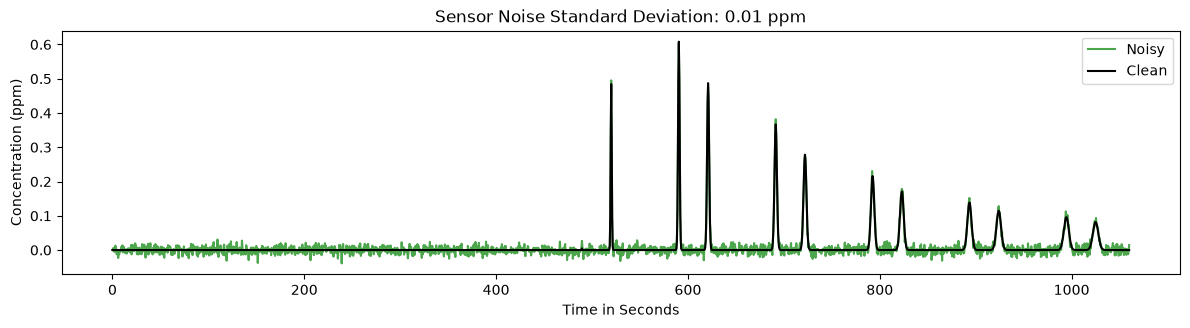

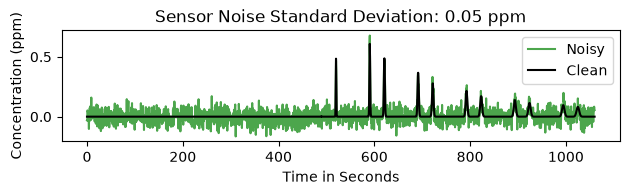

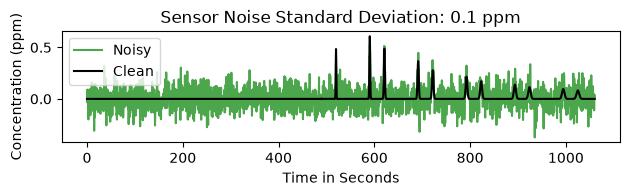

In [4]:
## Plotting time: comparing the clean signal with one noisy repeat at each noise level ##

plt.figure(figsize=(12, 9))

for i in range(len(noiseLevels)):
    plt.subplot(3, 1, i + 1)
    plt.plot(sampleTimes, noisyData[i, 0], color='green', alpha=0.7, label='Noisy')
    plt.plot(sampleTimes, cleanData, color='black', linewidth=1.5, label='Clean')
    plt.title('Sensor Noise Standard Deviation: ' + str(noiseLevels[i]) + ' ppm')
    plt.xlabel('Time in Seconds')
    plt.ylabel('Concentration (ppm)')
    plt.legend()
    plt.tight_layout()
    plt.show()
    
# plots seen below #

In [5]:
## Shuffle repeat indices so thre split is reproducible ##

rng = np.random.default_rng(42)
repeatIndices = rng.permutation(noisyData.shape[1])

# Lets split the data now #
trainIndices = repeatIndices[:60]
validateIndices = repeatIndices[60:80]
testIndices = repeatIndices[80:]

# seperate the noisy measurements #
trainData = noisyData[:, trainIndices, :]
validateData = noisyData[:, validateIndices, :]
testData = noisyData[:, testIndices, :]

#shapes of each set #
print('Training Data Shape:', trainData.shape)
print('Validation Data Shape:', validateData.shape)
print('Testing Data Shape:', testData.shape)

Training Data Shape: (3, 60, 2121)
Validation Data Shape: (3, 20, 2121)
Testing Data Shape: (3, 20, 2121)


### Preparing Measurement Windows for PCA

In [6]:
windowSize = 21
trainWindows = []
validateWindows = []

# Creating windows seperately for each noise level #
for i in range(len(noiseLevels)):
    trainLevel = []
    validateLevel = []
    
    # Create windows within each training flight (f) #
    for f in trainData[i]:
        for s in range(len(f) - windowSize + 1):
            trainLevel.append(f[s:s + windowSize])
            
    # Create windows within each validation flight (v) #
    for v in validateData[i]:
        for s in range(len(v) - windowSize + 1):
            validateLevel.append(v[s:s + windowSize])
          
    trainWindows.append(trainLevel)
    validateWindows.append(validateLevel)
    
# Make these lists made above into numpy arrays #
trainWindows = np.array(trainWindows)
validateWindows = np.array(validateWindows)

print('Training Windows Shape:', trainWindows.shape)
print('Validation Windows Shape:', validateWindows.shape)

Training Windows Shape: (3, 126060, 21)
Validation Windows Shape: (3, 42020, 21)


### PCA Time

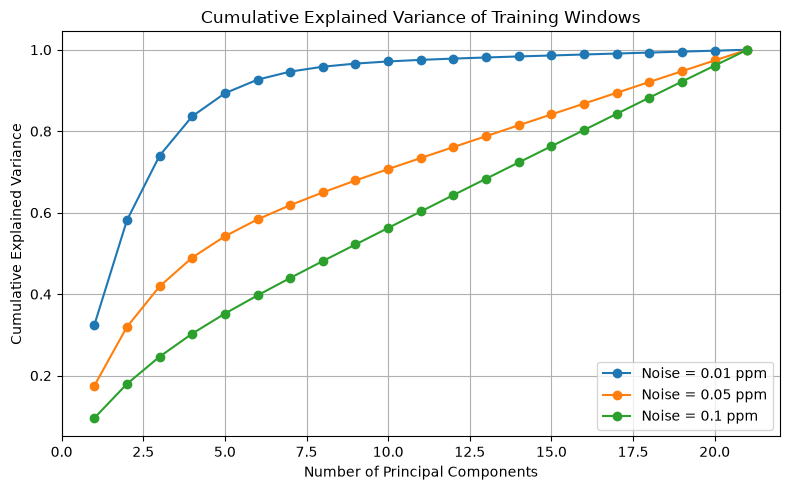

In [7]:
pcaModels = []
plt.figure(figsize=(8, 5))

for i in range(len(noiseLevels)):
    pca = PCA(n_components=windowSize, svd_solver='full')
    pca.fit(trainWindows[i])
    pcaModels.append(pca)
    
    # Cumulative Explained Variance: #
    cumVar = np.cumsum(pca.explained_variance_ratio_)
    
    plt.plot(range(1, windowSize + 1), cumVar, marker='o', label='Noise = ' + str(noiseLevels[i]) + ' ppm')
    
plt.title('Cumulative Explained Variance of Training Windows')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [8]:
## Reconstruct a full flight by averaging overlapping windows ##

def reconstructFlight(flight, pca, componentCount):
    windows = []
    
    for start in range(len(flight) - windowSize + 1):
        windows.append(flight[start:start + windowSize])
        
    windows = np.array(windows)
    
    # Show windows into PCA coord. and discard components beyond selected count #
    score = pca.transform(windows)
    score[:, componentCount:] = 0
    
    # Reconstruct windows and add back the saved training means #
    rebuiltWindows = pca.inverse_transform(score)
    
    #combine overlapping windows into the original flight length #
    rebuiltFlight = np.zeros(len(flight))
    counts = np.zeros(len(flight))
    
    for start in range(len(windows)):
        rebuiltFlight[start:start + windowSize] += rebuiltWindows[start]
        counts[start:start + windowSize] += 1
        
    return rebuiltFlight / counts

In [9]:
## Compare component counts using validation flights ##

componentCounts = np.arange(windowSize + 1)
validationRMSE = np.zeros((len(noiseLevels), len(componentCounts)))

for i in range(len(noiseLevels)):
    for k in componentCounts:
        squaredError = 0
        
        for flight in validateData[i]:
            rebuiltFlight = reconstructFlight(flight, pcaModels[i], k)
            squaredError += np.sum((rebuiltFlight - cleanData) ** 2)
            
        validationRMSE[i, k] = np.sqrt(squaredError / validateData[i].size)
        
# We want smallest RMSE #
bestComp = np.argmin(validationRMSE, axis=1)


for i in range(len(noiseLevels)):
    print('Noise Level (ppm):', noiseLevels[i])
    print('Selected Components:', bestComp[i])
    print('Validation RMSE:', validationRMSE[i, bestComp[i]])
    print('')

Noise Level (ppm): 0.01
Selected Components: 9
Validation RMSE: 0.006892511024982769

Noise Level (ppm): 0.05
Selected Components: 4
Validation RMSE: 0.024192743485637446

Noise Level (ppm): 0.1
Selected Components: 2
Validation RMSE: 0.036446906142318505



In [10]:
## Sotre reconstructed test flights and their errors

reconstructTest = np.zeros_like(testData)
noisyTestRMSE = np.zeros(len(noiseLevels))
pcaTestRMSE = np.zeros(len(noiseLevels))

for i in range(len(noiseLevels)):
    #Use the component count selected on validation data
    for j in range(testData.shape[1]):
        reconstructTest[i, j] = reconstructFlight(testData[i, j], pcaModels[i], bestComp[i])
        
    #Compare both versios with the clean simulation #
    noisyTestRMSE[i] = np.sqrt(np.mean((testData[i] - cleanData) ** 2))  
    pcaTestRMSE[i] = np.sqrt(np.mean((reconstructTest[i] - cleanData) ** 2))
    improve = 100 * (noisyTestRMSE[i] - pcaTestRMSE[i]) / noisyTestRMSE[i]
    
    print('Noise Level (ppm):', noiseLevels[i])
    print('Selected Components:', bestComp[i])
    print('Noisy Test RMSE:', noisyTestRMSE[i])
    print('PCA Test RMSE:', pcaTestRMSE[i])
    print('RMSE Reduction (%):', improve)
    print('')

Noise Level (ppm): 0.01
Selected Components: 9
Noisy Test RMSE: 0.010005719516279184
PCA Test RMSE: 0.006867049829596184
RMSE Reduction (%): 31.368755456081118

Noise Level (ppm): 0.05
Selected Components: 4
Noisy Test RMSE: 0.050011379609376065
PCA Test RMSE: 0.024367499411568547
RMSE Reduction (%): 51.27609035804291

Noise Level (ppm): 0.1
Selected Components: 2
Noisy Test RMSE: 0.09982642516606186
PCA Test RMSE: 0.03662288818428498
RMSE Reduction (%): 63.313433168259216



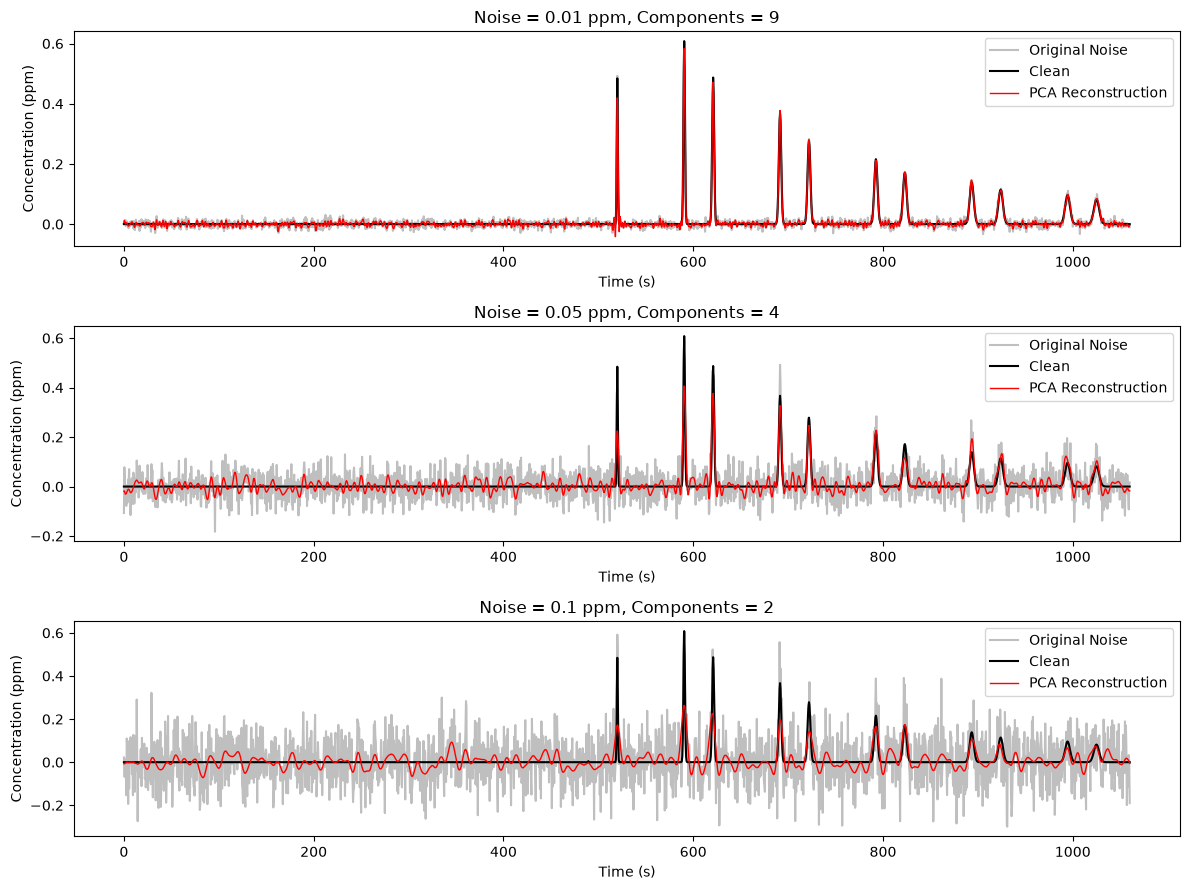

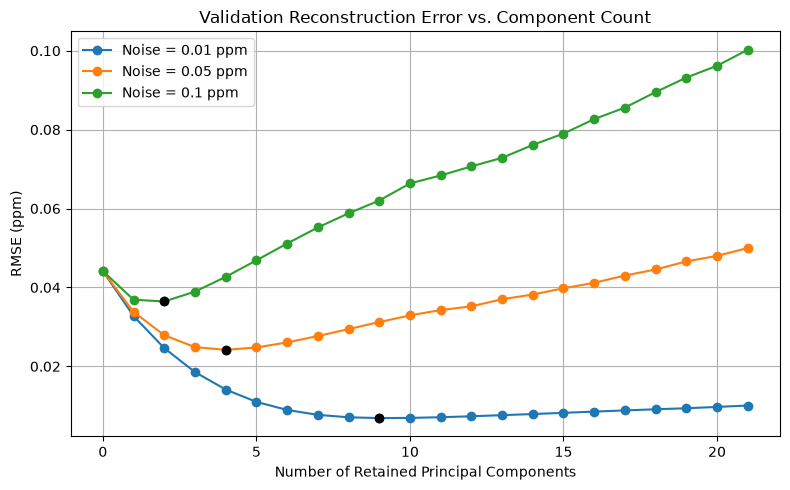

In [11]:
## PCA PLOTS !! ##
plt.figure(figsize=(12, 9))

for i in range(len(noiseLevels)):
    plt.subplot(3, 1, i + 1)

    plt.plot(sampleTimes, testData[i, 0], color='gray', alpha=0.5, label='Original Noise')
    plt.plot(sampleTimes, cleanData, color='black', linewidth=1.5, label='Clean')
    plt.plot(sampleTimes, reconstructTest[i, 0], color='red', linewidth=1, label='PCA Reconstruction')

    plt.title('Noise = ' + str(noiseLevels[i]) + ' ppm, Components = ' + str(bestComp[i]))
    plt.xlabel('Time (s)')
    plt.ylabel('Concentration (ppm)')
    plt.legend()

plt.tight_layout()
plt.show()

## Plotting validation error for each component count ##

plt.figure(figsize=(8, 5))

for i in range(len(noiseLevels)):
    plt.plot(componentCounts, validationRMSE[i], marker='o', label='Noise = ' + str(noiseLevels[i]) + ' ppm')
    plt.scatter(bestComp[i], validationRMSE[i, bestComp[i]], color='black', zorder=3)
    
plt.title('Validation Reconstruction Error vs. Component Count')
plt.xlabel('Number of Retained Principal Components')
plt.ylabel('RMSE (ppm)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Saving Results for Least Squares Analysis

In [12]:
outputFile = "Out/skylor_pca_results.npz"

np.savez_compressed(
    outputFile,
    y_noisy=testData,
    y_reconstructed=reconstructTest,
    y_clean=cleanData,
    noise_sigmas_ppm=noiseLevels,
    selected_components=bestComp,
    window_size=windowSize,
    test_indices=testIndices,
    train_indices=trainIndices,
    val_indices=validateIndices,
    component_counts=componentCounts,
    validation_rmse=validationRMSE,
    noisy_test_rmse=noisyTestRMSE,
    pca_test_rmse=pcaTestRMSE,
    traj=sampleLocations,
    t=sampleTimes,
    wind=meth_data['wind'],
    H=meth_data['H'],
    cand_xy=meth_data['cand_xy'],
    source_xy=meth_data['source_xy'],
    q_true=meth_data['q_true']
)

## Reopen the saved file and check the dimensions ##

with np.load(outputFile) as savedData:
    print('Noisy Test Shape:', savedData['y_noisy'].shape)
    print('Reconstructed Test Shape:',
          savedData['y_reconstructed'].shape)
    print('Source-Receptor Matrix Shape:', savedData['H'].shape)

    assert savedData['y_noisy'].shape == savedData['y_reconstructed'].shape
    assert savedData['y_reconstructed'].shape[-1] == savedData['H'].shape[0]

print('Saved:', outputFile)

Noisy Test Shape: (3, 20, 2121)
Reconstructed Test Shape: (3, 20, 2121)
Source-Receptor Matrix Shape: (2121, 625)
Saved: Out/skylor_pca_results.npz


__PCA Analysis----->__ During this coding portion of our final semester project, I was in charge of cleaning and preprocessing the simulated methane concentration data and applying PCA to investigate whether signal reconstruction could reduce sensor noise while preserving useful plume information. Overall, PCA reconstruction reduced test concentration RMSE by approximately 31.37%, 51.28%, and 63.31% at noise standard deviations of 0.01, 0.05, and 0.10 ppm. Validation selected 9, 4, and 2 retained components. Reconstruction used overlapping 21-measurement windows, with overlapping estimates averaged to recover each full flight. Although background noise did decrease, some narrow plume peaks were reduced, particularly at higher levels of noise. These results apply to independent noise realizations of one fixed simulated plume. Following this will be least-squares analysis, which will determine whether reconstruction also improves emission-rate estimates. 